# code_206 · Identify the shift before choosing a response

**Book:** section 39.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_39_GUIDE.md), [execution evidence](../CHAPTER_39_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_206).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Robustness contracts identify the source population, challenge mechanism, allowed adaptation information, physical checks and fallback. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8006;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8006


## Construct observable and unobservable changes
 Fit a fixed histogram classifier to1,600 source records with normalized load uniform[-2,2], binary material and noisy finding probability logistic(-1+1.4load+0.8material). Assess800 familiar records,800 covariate-shift records with load uniform[0,2] and material prevalence0.8, and800 unsupported records with load[2.2,4]. All retain the response law. A conditional-shift challenge reuses exactly the familiar input array but draws labels with the load effect reversed. Inputs alone cannot distinguish those two laws: every deterministic input diagnostic is identical. Report Brier, error, prevalence and a declared source-range rejection fraction; this range is an engineering envelope, not an inferred density theorem.


,n,Brier,error,prevalence,outside_declared_range
Familiar,800.0,0.145137,0.19875,0.4250,0.0
Covariate,800.0,0.178727,0.24500,0.7200,0.0
Conditional,800.0,0.484303,0.70125,0.4125,0.0
Unsupported,800.0,0.025781,0.02500,0.9750,1.0


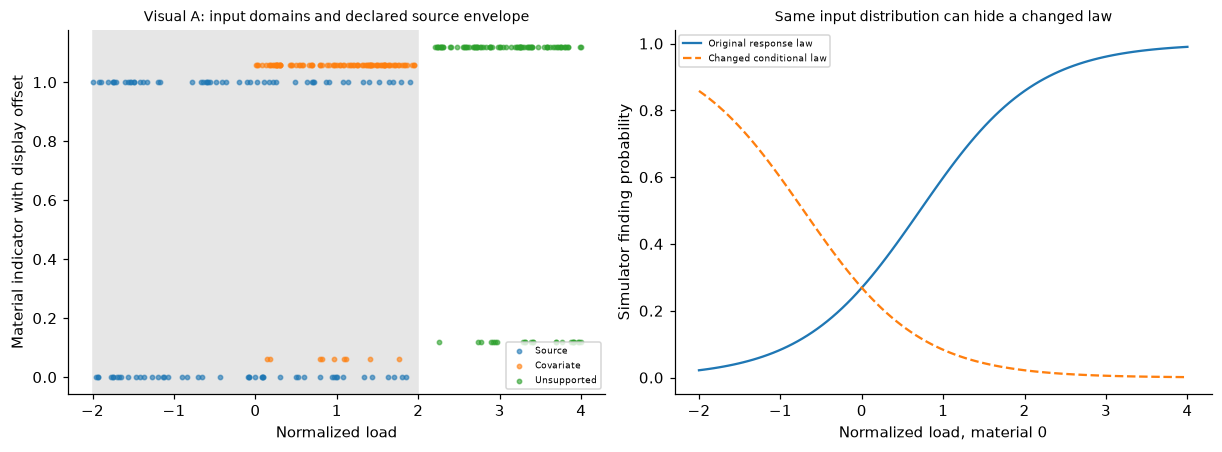

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
def cohort(n,low=-2,high=2,material=.5):
    x=np.c_[rng.uniform(low,high,n),rng.binomial(1,material,n)];p=expit(-1+1.4*x[:,0]+.8*x[:,1]);return x,rng.binomial(1,p)
xs,ys=cohort(1600);familiar,yfam=cohort(800);cov,ycov=cohort(800,0,2,.8);outside,yout=cohort(800,2.2,4,.8);conditional=familiar.copy();ycond=rng.binomial(1,expit(-1-1.4*conditional[:,0]+.8*conditional[:,1]));assert np.array_equal(familiar,conditional);model=HistGradientBoostingClassifier(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);domains={'Familiar':(familiar,yfam),'Covariate':(cov,ycov),'Conditional':(conditional,ycond),'Unsupported':(outside,yout)};scores={}
for name,(x,y) in domains.items():
    p=model.predict_proba(x)[:,1];scores[name]={'n':len(y),'Brier':float(np.mean((p-y)**2)),'error':float(np.mean((p>=.5)!=y)),'prevalence':float(y.mean()),'outside_declared_range':float(np.mean((x[:,0]<-2)|(x[:,0]>2)))}
assert scores['Familiar']['outside_declared_range']==scores['Conditional']['outside_declared_range']==0;RESULTS.update(source_records=1600,domain_scores=scores,conditional_inputs_byte_identical=True,conditional_shift_observable_from_inputs_alone=False);display(pd.DataFrame(scores).T);fig,axes=plt.subplots(1,2,figsize=(11,4))
for j,(name,x) in enumerate([('Source',xs),('Covariate',cov),('Unsupported',outside)]):axes[0].scatter(x[:100,0],x[:100,1]+j*.06,s=8,alpha=.6,label=name)
axes[0].axvspan(-2,2,color='.9',zorder=-2);axes[0].set(xlabel='Normalized load',ylabel='Material indicator with display offset',title='Visual A: input domains and declared source envelope');axes[0].legend(fontsize=6);grid=np.linspace(-2,4,100);axes[1].plot(grid,expit(-1+1.4*grid),label='Original response law');axes[1].plot(grid,expit(-1-1.4*grid),'--',label='Changed conditional law');axes[1].set(xlabel='Normalized load, material 0',ylabel='Simulator finding probability',title='Same input distribution can hide a changed law');axes[1].legend(fontsize=6);plt.show()


## Label shift is a different factorization
 Independently generate a binary label with prior0.3 at source and0.7 at target, then sample a sensor from Normal(-1,1) for negatives or Normal(1,1) for positives. The class-conditional sensor laws stay fixed exactly by construction. Fit logistic regression to2,000 source records. A deliberately known simulator target prior permits an oracle prior-odds correction; label it as oracle, not a prior estimated without labels. Assess1,000 independent target records and compare the original and corrected probabilities. This separate experiment illustrates label-shift assumptions; the prior correction is not valid for the preceding reversed conditional law. No target outcome chooses a threshold or model.


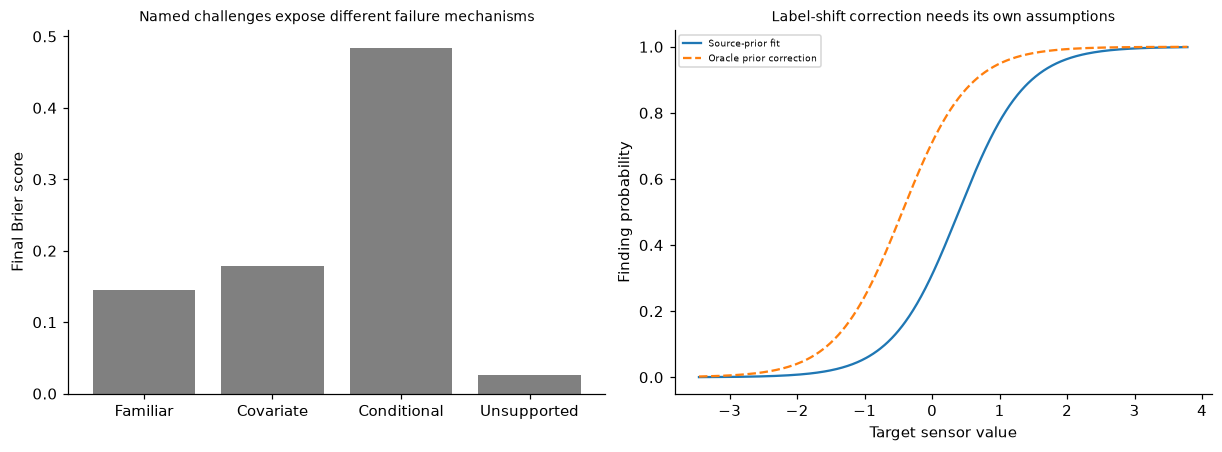

In [3]:
def labelcohort(n,prior):
    y=rng.binomial(1,prior,n);x=rng.normal(2*y-1,1)[:,None];return x,y
lx,ly=labelcohort(2000,.3);lt,lyt=labelcohort(1000,.7);labelmodel=LogisticRegression(C=10,max_iter=300).fit(lx,ly);p=labelmodel.predict_proba(lt)[:,1];odds=np.clip(p,1e-10,1-1e-10)/(1-np.clip(p,1e-10,1-1e-10));ratio=(.7/.3)/(.3/.7);corrected=odds*ratio/(1+odds*ratio);assert np.all((corrected>0)&(corrected<1));assert np.all(corrected>p);rows={name:{'Brier':float(np.mean((pred-lyt)**2)),'mean_probability':float(pred.mean())} for name,pred in [('Source prior',p),('Oracle target prior',corrected)]};RESULTS.update(label_shift_source_prior=.3,label_shift_target_prior=.7,label_shift_target_empirical_prevalence=float(lyt.mean()),label_shift_scores=rows,prior_correction_uses_oracle_simulator_prior=True);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(4),[scores[k]['Brier'] for k in scores],color='.5');axes[0].set(xticks=range(4),xticklabels=list(scores),ylabel='Final Brier score',title='Named challenges expose different failure mechanisms');order=np.argsort(lt[:,0]);axes[1].plot(lt[order,0],p[order],label='Source-prior fit');axes[1].plot(lt[order,0],corrected[order],'--',label='Oracle prior correction');axes[1].set(xlabel='Target sensor value',ylabel='Finding probability',title='Label-shift correction needs its own assumptions');axes[1].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_206','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['source-only classifier assessed on separate covariate and conditional shifts', 'identical observed inputs with changed response law as an observability control', 'exact class-conditional label-shift generator and prior correction', 'source-support map and independent label-dependent diagnostics'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["source-only classifier assessed on separate covariate and conditional shifts", "identical observed inputs with changed response law as an observability control", "exact class-conditional label-shift generator and prior correction", "source-support map and independent label-dependent diagnostics"], "elapsed_seconds": 0.411, "example_id": "code_206", "hardware": "Darwin arm64 CPU", "results": {"conditional_inputs_byte_identical": true, "conditional_shift_observable_from_inputs_alone": false, "domain_scores": {"Conditional": {"Brier": 0.48430330830123713, "error": 0.70125, "n": 800, "outside_declared_range": 0.0, "prevalence": 0.4125}, "Covariate": {"Brier": 0.1787268696846705, "error": 0.245, "n": 800, "outside_declared_range": 0.0, "prevalence": 0.72}, "Familiar": {"Brier": 0.14513740658926064, "error": 0.19875, "n": 800, "outside_declared_range": 0.0, "prevalence": 0.425}, "Unsupported": {"Brier": 0.025781129352213824, "error": 0.025, 